In [1]:
#------------------------裁剪RAMCO2.3P2------------------保留格陵兰的---------albedo--------------------------nc文件--------------
import numpy as np
import xarray as xr
import geopandas as gpd
from shapely.vectorized import contains
from pyproj import Transformer
import os
import warnings
warnings.filterwarnings("ignore")

# 配置路径
nc_path = r"F:\TUB\greenlandProject\ERA5LAND\alb19582017RACMO2.3p2\albedo.nc"
shp_path = r"E:\TUB\greenland\Greenland_shp\Gboundry.shp"
output_path = r"F:\TUB\greenlandProject\ERA5LAND\alb19582017RACMO2.3p2\greenland_albedo_cropped.nc"

def memory_optimized_crop():
    """内存优化的裁剪流程"""
    
    # 1. 加载最小必要数据 --------------------------------------------------
    print("步骤1/4: 加载数据...")
    with xr.open_dataset(nc_path) as ds:
        print("数据集维度结构:", ds.dims)
        print("反照率变量维度:", ds['alb'].dims)
        
        # 获取2D经纬度网格
        lon = ds['lon'].values  # 应该是(566, 438)的2D数组
        lat = ds['lat'].values  # 应该是(566, 438)的2D数组
        
        # 获取反照率数据 (跳过不需要的维度)
        alb = ds['alb'].values  # 完整形状应该是(60, 1, 566, 438)
        
        # 检查实际形状
        print(f"经度数组形状: {lon.shape}")
        print(f"纬度数组形状: {lat.shape}")
        print(f"反照率数组形状: {alb.shape}")
    
    # 2. 准备地理掩码 -----------------------------------------------------
    print("步骤2/4: 生成地理掩码...")
    gdf = gpd.read_file(shp_path)
    
    # 坐标转换器 (假设SHP是WGS84)
    transformer = Transformer.from_crs("EPSG:4326", "EPSG:4326", always_xy=True)
    
    # 分块处理避免内存爆炸
    chunk_size = 50  # 更小的分块大小以适应旧电脑
    mask = np.zeros(lon.shape, dtype=bool)
    
    for i in range(0, lon.shape[0], chunk_size):
        for j in range(0, lon.shape[1], chunk_size):
            i_end = min(i + chunk_size, lon.shape[0])
            j_end = min(j + chunk_size, lon.shape[1])
            
            # 转换当前块的坐标
            lon_chunk = lon[i:i_end, j:j_end]
            lat_chunk = lat[i:i_end, j:j_end]
            
            # 向量化空间查询
            mask[i:i_end, j:j_end] = contains(
                gdf.geometry[0],  # 假设只有一个多边形
                lon_chunk.ravel(),
                lat_chunk.ravel()
            ).reshape(lon_chunk.shape)
            
            # 及时释放临时变量
            del lon_chunk, lat_chunk
    
    # 3. 应用掩码并保存 ---------------------------------------------------
    print("步骤3/4: 应用掩码...")
    
    # 创建输出数据集
    output_ds = xr.Dataset()
    
    # 复制时间维度
    with xr.open_dataset(nc_path) as ds:
        output_ds['time'] = ds['time']
        output_ds['height'] = ds['height']
        
        # 创建裁剪后的反照率变量
        alb_cropped = np.zeros_like(alb)
        for t in range(alb.shape[0]):  # 时间维度
            for h in range(alb.shape[1]):  # 高度维度
                alb_cropped[t, h] = np.where(mask, alb[t, h], np.nan)
        
        output_ds['alb'] = (('time', 'height', 'rlat', 'rlon'), alb_cropped)
        
        # 复制坐标变量
        output_ds['lon'] = (('rlat', 'rlon'), lon)
        output_ds['lat'] = (('rlat', 'rlon'), lat)
        
        # 复制全局属性
        output_ds.attrs = ds.attrs
    
    # 4. 保存结果 --------------------------------------------------------
    print("步骤4/4: 保存结果...")
    
    # 分块写入以减少内存使用
    encoding = {
        'alb': {'zlib': True, 'complevel': 1},
        'time': {'dtype': 'float32'},
        'lon': {'dtype': 'float32'},
        'lat': {'dtype': 'float32'}
    }
    
    output_ds.to_netcdf(output_path, encoding=encoding)
    print(f"裁剪完成！结果已保存至: {output_path}")

# 执行裁剪
memory_optimized_crop()

步骤1/4: 加载数据...


FileNotFoundError: [Errno 2] No such file or directory: 'F:\\TUB\\greenlandProject\\ERA5LAND\\alb19582017RACMO2.3p2\\albedo.nc'

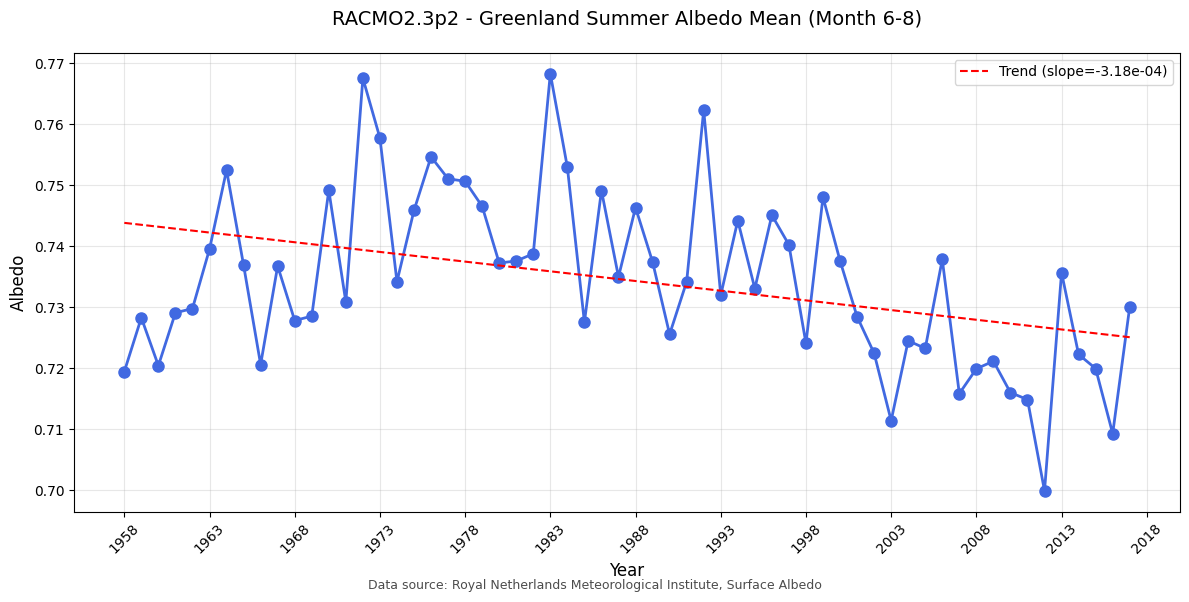

In [ ]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np

# 文件路径
file_path = r"C:\greenland\alb19582017RACMO2.3p2\greenland_albedo_cropped.nc"

# 打开数据集
ds = xr.open_dataset(file_path)

# 计算空间均值（对rlat和rlon取平均）
# 使用skipna=True跳过缺失值
annual_albedo = ds['alb'].mean(dim=['rlat', 'rlon'], skipna=True)

# 由于每年只有一个时间点，我们不需要groupby，直接按时间排序即可
# 但为了明确起见，我们可以提取年份作为x轴
years = ds['time.year'].values
albedo_values = annual_albedo.values.squeeze()  # 移除高度维度

# 创建图表
plt.figure(figsize=(12, 6))
plt.plot(years, albedo_values, marker='o', linestyle='-', color='royalblue', linewidth=2, markersize=8)

# 添加趋势线
z = np.polyfit(years, albedo_values, 1)
p = np.poly1d(z)
plt.plot(years, p(years), linestyle='--', color='red', linewidth=1.5, 
         label=f'Trend (slope={z[0]:.2e})')

# 美化图表
plt.title('RACMO2.3p2 - Greenland Summer Albedo Mean (Month 6-8)', fontsize=14, pad=20)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Albedo', fontsize=12)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=10)

# 调整x轴刻度
plt.xticks(np.arange(1958, 2020, 5), rotation=45)

# 添加数据来源信息
plt.figtext(0.5, 0.01, f"Data source: {ds.attrs.get('institution', 'Unknown')}, {ds.attrs.get('title', '')}", 
            ha="center", fontsize=9, alpha=0.7)

plt.tight_layout()
plt.show()

# 关闭数据集
ds.close()

CSV 已保存：C:\greenland\alb19582017RACMO2.3p2\JJA_albedo_1958_2020.csv


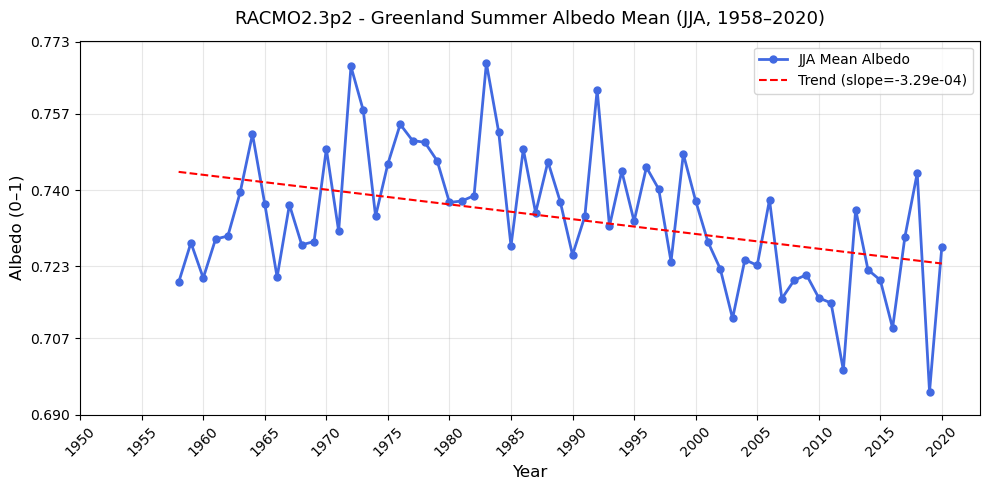

图已保存：C:\greenland\alb19582017RACMO2.3p2\JJA_albedo_1958_2020.png


In [6]:
# -*- coding: utf-8 -*-
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

# ========== 路径 ==========
file_path = r"C:\greenland\alb19582017RACMO2.3p2\greenland_albedo_cropped.nc"
out_dir = Path(r"C:\greenland\alb19582017RACMO2.3p2")
csv_path = out_dir / "JJA_albedo_1958_2020.csv"
fig_path = out_dir / "JJA_albedo_1958_2020.png"

# 你给的 2017–2020 JJA 域平均（会覆盖 2017，并追加 2018–2020）
new_points = {
    2017: 0.7296,
    2018: 0.7438,
    2019: 0.6951,
    2020: 0.7274,
}

# ========== 读数 & 计算 1958–2017 ==========
ds = xr.open_dataset(file_path)

# 时间轴名称（优先 'time'，否则尝试 'valid_time'）
tname = "time" if "time" in ds.variables or "time" in ds.coords else \
        ("valid_time" if "valid_time" in ds.variables or "valid_time" in ds.coords else None)
if tname is None:
    # 兜底：找 datetime64 的坐标
    for name, coord in ds.coords.items():
        if np.issubdtype(coord.dtype, np.datetime64):
            tname = name
            break
    if tname is None:
        raise KeyError("未找到时间维度（如 'time' 或 'valid_time'）。")

# 反照率变量（默认 'alb'）
vname = "alb" if "alb" in ds.data_vars else None
if vname is None:
    # 兜底：找名字里带 'alb' 的变量
    for k in ds.data_vars:
        if "alb" in k.lower():
            vname = k
            break
if vname is None:
    raise KeyError(f"未发现反照率变量（如 'alb'）。可用变量：{list(ds.data_vars)}")

da = ds[vname]

# 计算空间均值（对 rlat/rlon 或 lat/lon/x/y 等非时间维求平均）
spatial_dims = [d for d in da.dims if d != tname and d.lower() in ("rlat","rlon","lat","lon","x","y")]
if len(spatial_dims) == 0:
    # 如果变量只剩时间一维，就不再取均值
    pass
else:
    da = da.mean(dim=spatial_dims, skipna=True)

# 移除多余维度（如高度维），只保留时间轴
for d in list(da.dims):
    if d != tname:
        da = da.mean(dim=d, skipna=True)
da = da.squeeze()

# 年份与数值（假定此 nc 已是“每年一个 JJA 值”）
years_all = ds[tname].dt.year.values.astype(int)
vals_all = da.values.astype(float)

ds.close()

# 仅保留 1958–2017
mask_5817 = (years_all >= 1958) & (years_all <= 2017)
years_5817 = years_all[mask_5817]
vals_5817 = vals_all[mask_5817]

# ========== 覆盖 2017，拼接 2018–2020 ==========
df = pd.DataFrame({"year": years_5817, "albedo_JJA": vals_5817})

# 覆盖 2017
if 2017 in df["year"].values:
    df.loc[df["year"] == 2017, "albedo_JJA"] = new_points[2017]
else:
    df = pd.concat([df, pd.DataFrame([{"year": 2017, "albedo_JJA": new_points[2017]}])],
                   ignore_index=True)

# 追加 2018–2020
add_rows = [{"year": y, "albedo_JJA": v} for y, v in new_points.items() if y > 2017]
df = pd.concat([df, pd.DataFrame(add_rows)], ignore_index=True)

# 排序 & 去重
df = df.drop_duplicates(subset=["year"], keep="last").sort_values("year").reset_index(drop=True)

# ========== 导出 CSV ==========
out_dir.mkdir(parents=True, exist_ok=True)
df.to_csv(csv_path, index=False)
print(f"CSV 已保存：{csv_path}")

# ========== 画折线图（y 轴自适应到 ~0.69–0.78）==========
plt.figure(figsize=(10, 5))
plt.plot(df["year"], df["albedo_JJA"], marker='o', linestyle='-', color='royalblue',
         linewidth=2, markersize=5, label="JJA Mean Albedo")

# 趋势线（全时段）
z = np.polyfit(df["year"].values, df["albedo_JJA"].values, 1)
p = np.poly1d(z)
plt.plot(df["year"], p(df["year"]), linestyle='--', color='red', linewidth=1.5,
         label=f"Trend (slope={z[0]:.2e})")

plt.title("RACMO2.3p2 - Greenland Summer Albedo Mean (JJA, 1958–2020)", fontsize=13, pad=12)
plt.xlabel("Year", fontsize=12)
plt.ylabel("Albedo (0–1)", fontsize=12)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=10)
plt.xticks(np.arange(1950, 2025, 5), rotation=45)

# —— y 轴自适应（限制在 0.69–0.78，并加 0.005 边距）——
ymin = max(0.69, float(df["albedo_JJA"].min()) - 0.005)
ymax = min(0.78, float(df["albedo_JJA"].max()) + 0.005)
if (ymax - ymin) < 0.01:  # 防止极端过窄
    ymin = max(0.69, ymin - 0.005)
    ymax = min(0.78, ymax + 0.005)
plt.ylim(ymin, ymax)
plt.yticks(np.round(np.linspace(ymin, ymax, 6), 3))

plt.tight_layout()
plt.savefig(fig_path, dpi=200)
plt.show()
print(f"图已保存：{fig_path}")


=== 坐标信息 ===
旋转坐标范围: rlat=[0.00, 565.00]
旋转坐标范围: rlon=[0.00, 437.00]
经纬度范围: lon=[-105.70, 34.11]
经纬度范围: lat=[55.57, 85.85]

=== 中心点坐标 ===
旋转坐标 (rlat, rlon) = (283.00, 219.00)
实际经纬度 (lat, lon) = (71.73, -34.63)


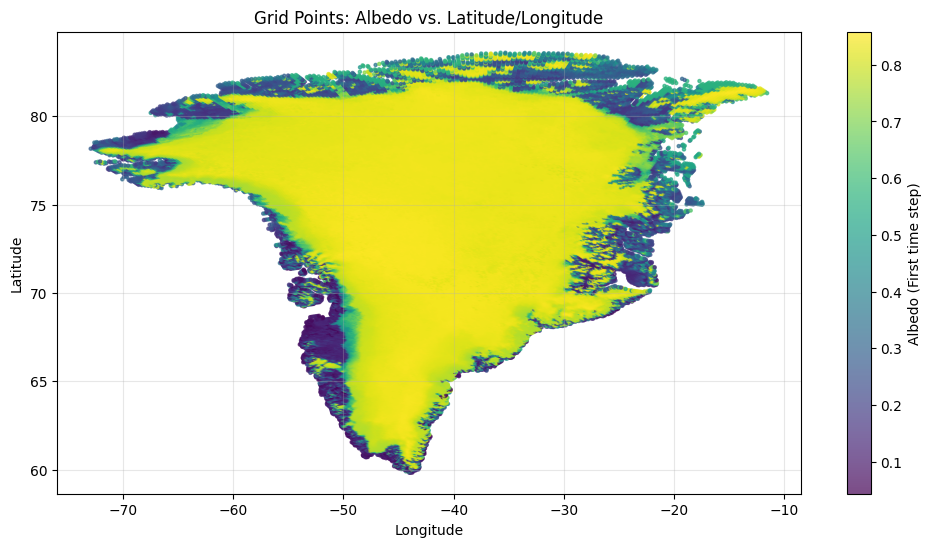


=== 反照率与经纬度示例（2000年）===
反照率范围: [0.04, 0.87]
高反照率区域（>0.6）的经纬度示例:
  (rlat_idx, rlon_idx)=(49, 134) → (lat, lon)=(59.87, -44.04)
  (rlat_idx, rlon_idx)=(50, 132) → (lat, lon)=(59.91, -44.24)
  (rlat_idx, rlon_idx)=(50, 135) → (lat, lon)=(59.92, -43.95)


In [4]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np

# 打开文件
file_path = r"F:\TUB\greenlandProject\ERA5LAND\alb19582017RACMO2.3p2\greenland_albedo_cropped.nc"
ds = xr.open_dataset(file_path)

# 1. 打印基本坐标信息
print("=== 坐标信息 ===")
print(f"旋转坐标范围: rlat=[{ds.rlat.min().item():.2f}, {ds.rlat.max().item():.2f}]")
print(f"旋转坐标范围: rlon=[{ds.rlon.min().item():.2f}, {ds.rlon.max().item():.2f}]")
print(f"经纬度范围: lon=[{ds.lon.min().item():.2f}, {ds.lon.max().item():.2f}]")
print(f"经纬度范围: lat=[{ds.lat.min().item():.2f}, {ds.lat.max().item():.2f}]")

# 2. 检查某个点的映射关系（例如中心点）
# 由于 rlat 和 rlon 不是坐标变量，我们通过索引访问
rlat_center = ds.rlat[len(ds.rlat)//2].item()
rlon_center = ds.rlon[len(ds.rlon)//2].item()

# 获取中心点的经纬度
lat_center = ds.lat[len(ds.rlat)//2, len(ds.rlon)//2].item()
lon_center = ds.lon[len(ds.rlat)//2, len(ds.rlon)//2].item()

print("\n=== 中心点坐标 ===")
print(f"旋转坐标 (rlat, rlon) = ({rlat_center:.2f}, {rlon_center:.2f})")
print(f"实际经纬度 (lat, lon) = ({lat_center:.2f}, {lon_center:.2f})")

# 3. 可视化格陵兰的经纬度网格
plt.figure(figsize=(12, 6))
plt.scatter(ds.lon.values, ds.lat.values, c=ds.alb.isel(time=0, height=0).values, 
            s=5, cmap='viridis', alpha=0.7)
plt.colorbar(label='Albedo (First time step)')
plt.title("Grid Points: Albedo vs. Latitude/Longitude")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(alpha=0.3)
plt.show()

# 4. 检查反照率数据与经纬度的关系（示例：提取某一年的数据）
year = 2000
time_idx = np.where(ds.time.dt.year == year)[0][0]
albedo_data = ds.alb.isel(time=time_idx, height=0).values

print(f"\n=== 反照率与经纬度示例（{year}年）===")
print(f"反照率范围: [{np.nanmin(albedo_data):.2f}, {np.nanmax(albedo_data):.2f}]")
print(f"高反照率区域（>0.6）的经纬度示例:")
high_albedo = np.where(albedo_data > 0.6)
for i in range(3):  # 打印前3个高反照率点
    rlat_idx, rlon_idx = high_albedo[0][i], high_albedo[1][i]
    lat = ds.lat[rlat_idx, rlon_idx].item()
    lon = ds.lon[rlat_idx, rlon_idx].item()
    print(f"  (rlat_idx, rlon_idx)=({rlat_idx}, {rlon_idx}) → (lat, lon)=({lat:.2f}, {lon:.2f})")

# 关闭数据集
ds.close()

In [6]:
import pandas as pd

# 1. Read the original file
file_path = r"F:\TUB\greenlandProject\ERA5LAND\merged_allfeature.csv"
df = pd.read_csv(file_path)

# 2. Keep only the required columns
required_columns = ['longitude', 'latitude', 'year', 'month', 'albedo', 'station']
df = df[required_columns]

# 3. Filter groups that have June, July, and August data
def has_summer_months(group):
    months = group['month'].unique()
    return set([6, 7, 8]).issubset(set(months))

filtered_groups = df.groupby(['station', 'year']).filter(has_summer_months)

# 4. Calculate the mean albedo for summer months (June, July, August)
def calculate_summer_mean(group):
    summer_data = group[group['month'].isin([6, 7, 8])]
    mean_albedo = summer_data['albedo'].mean()
    # Return only new columns (excluding 'year', which is already in the index)
    return pd.Series({
        'longitude': group['longitude'].iloc[0],
        'latitude': group['latitude'].iloc[0],
        'albedo': mean_albedo
    })

# Apply the calculation
result_df = filtered_groups.groupby(['station', 'year']).apply(calculate_summer_mean).reset_index()

# 5. Keep only the final required columns
final_columns = ['longitude', 'latitude', 'year', 'albedo']
result_df = result_df[final_columns]

# 6. Save to a new CSV
output_path = r"F:\TUB\greenlandProject\ERA5LAND\alb19582017RACMO2.3p2\summer_albedo_mean.csv"
result_df.to_csv(output_path, index=False)

print(f"Processing complete. Results saved to {output_path}")

Processing complete. Results saved to F:\TUB\greenlandProject\ERA5LAND\summer_albedo_mean.csv


C:\Users\11823\AppData\Local\Temp\ipykernel_12636\1665623662.py:30: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  result_df = filtered_groups.groupby(['station', 'year']).apply(calculate_summer_mean).reset_index()



成功匹配 398/642 个数据点
   year    csv_lon    csv_lat  nc_albedo  csv_albedo  distance_km
0  1995 -61.115896  77.181945   0.851916    0.833833      5.95627
1  1996 -61.115896  77.181945   0.866551    0.839100      5.95627
2  1997 -61.115896  77.181945   0.856432    0.827300      5.95627
3  1999 -61.115896  77.181945   0.846302    0.824767      5.95627
4  2000 -61.115896  77.181945   0.853372    0.821100      5.95627


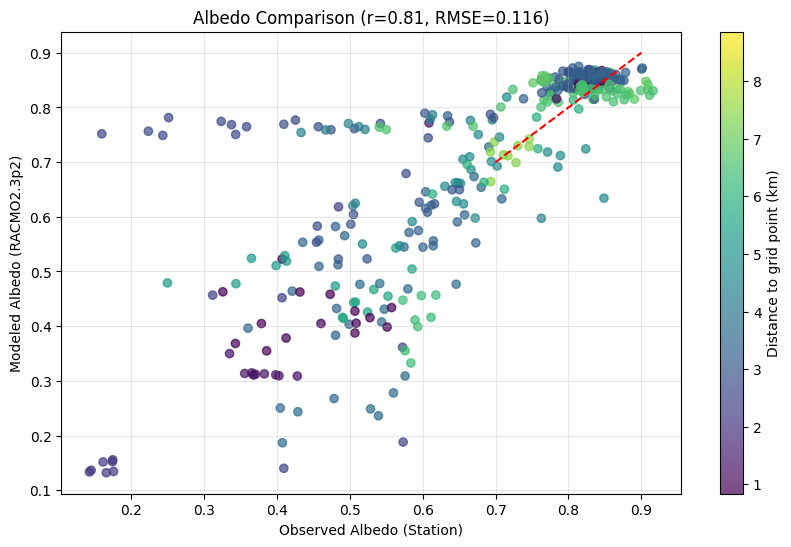

In [14]:
import xarray as xr
import pandas as pd
import numpy as np
from scipy.spatial import KDTree
import matplotlib.pyplot as plt

# 1. 加载数据
nc_path = r"F:\TUB\greenlandProject\ERA5LAND\alb19582017RACMO2.3p2\greenland_albedo_cropped.nc"
csv_path = r"F:\TUB\greenlandProject\ERA5LAND\alb19582017RACMO2.3p2\summer_albedo_mean.csv"

ds = xr.open_dataset(nc_path)
df = pd.read_csv(csv_path)

# 2. 转换CSV年份为整数
df['year'] = df['year'].astype(int)

# 3. 准备NetCDF网格点
valid_mask = (~np.isnan(ds.lon.values)) & (~np.isnan(ds.lat.values))
nc_lons_valid = ds.lon.values[valid_mask]
nc_lats_valid = ds.lat.values[valid_mask]
nc_points = np.column_stack([nc_lons_valid, nc_lats_valid])
tree = KDTree(nc_points)

# 4. 对每个CSV点进行处理
results = []
for idx, row in df.iterrows():
    try:
        # 获取坐标和年份（确保为整数）
        csv_lon, csv_lat = row['longitude'], row['latitude']
        year = int(row['year'])
        
        # 空间匹配：找到最近的网格点
        dist, idx = tree.query([[csv_lon, csv_lat]])
        nearest_lon, nearest_lat = nc_lons_valid[idx[0]], nc_lats_valid[idx[0]]
        
        # 获取原始网格索引
        original_idx = np.where((ds.lon.values == nearest_lon) & 
                              (ds.lat.values == nearest_lat))
        rlat_idx, rlon_idx = original_idx[0][0], original_idx[1][0]
        
        # 时间匹配：找到对应年份的数据（每年只有7月16日一个时间点）
        nc_albedo = ds.alb.sel(time=str(year)).isel(
            height=0, 
            rlat=rlat_idx, 
            rlon=rlon_idx
        ).item()
        
        results.append({
            'year': year,
            'csv_lon': csv_lon,
            'csv_lat': csv_lat,
            'nc_lon': nearest_lon,
            'nc_lat': nearest_lat,
            'csv_albedo': row['albedo'],
            'nc_albedo': nc_albedo,
            'distance_km': dist[0] * 111  # 转换为公里
        })
        
    except Exception as e:
        #print(f"跳过 {row['year']} 年: {str(e)}")
        continue

# 5. 转换为DataFrame
result_df = pd.DataFrame(results)

if not result_df.empty:
    print(f"\n成功匹配 {len(result_df)}/{len(df)} 个数据点")
    print(result_df[['year', 'csv_lon', 'csv_lat', 'nc_albedo', 'csv_albedo', 'distance_km']].head())
    
    # 计算统计指标
    corr, _ = pearsonr(result_df['csv_albedo'], result_df['nc_albedo'])
    rmse = np.sqrt(np.mean((result_df['csv_albedo'] - result_df['nc_albedo'])**2))
    
    # 可视化
    plt.figure(figsize=(10, 6))
    plt.scatter(result_df['csv_albedo'], result_df['nc_albedo'], 
               c=result_df['distance_km'], cmap='viridis', alpha=0.7)
    plt.colorbar(label='Distance to grid point (km)')
    plt.plot([0.7, 0.9], [0.7, 0.9], 'r--')  # 1:1线
    plt.xlabel('Observed Albedo (Station)')
    plt.ylabel('Modeled Albedo (RACMO2.3p2)')
    plt.title(f'Albedo Comparison (r={corr:.2f}, RMSE={rmse:.3f})')
    plt.grid(alpha=0.3)
    plt.show()
    
    # 保存结果
    result_df.to_csv('albedo_comparison_results.csv', index=False)
else:
    print("\n没有匹配到任何数据点！")

# 关闭文件
ds.close()


成功匹配 398/642 个数据点
   year    csv_lon    csv_lat  nc_albedo  csv_albedo  distance_km
0  1995 -61.115896  77.181945   0.851916    0.833833      5.95627
1  1996 -61.115896  77.181945   0.866551    0.839100      5.95627
2  1997 -61.115896  77.181945   0.856432    0.827300      5.95627
3  1999 -61.115896  77.181945   0.846302    0.824767      5.95627
4  2000 -61.115896  77.181945   0.853372    0.821100      5.95627

统计指标:
皮尔逊相关系数: 0.815 (p=9.858e-96)
R²分数: 0.588
RMSE: 0.1156
MAE: 0.0714
偏差(Bias): 0.0200
线性回归: y = 0.869x + 0.110
回归R值: 0.815 (p=9.858e-96)


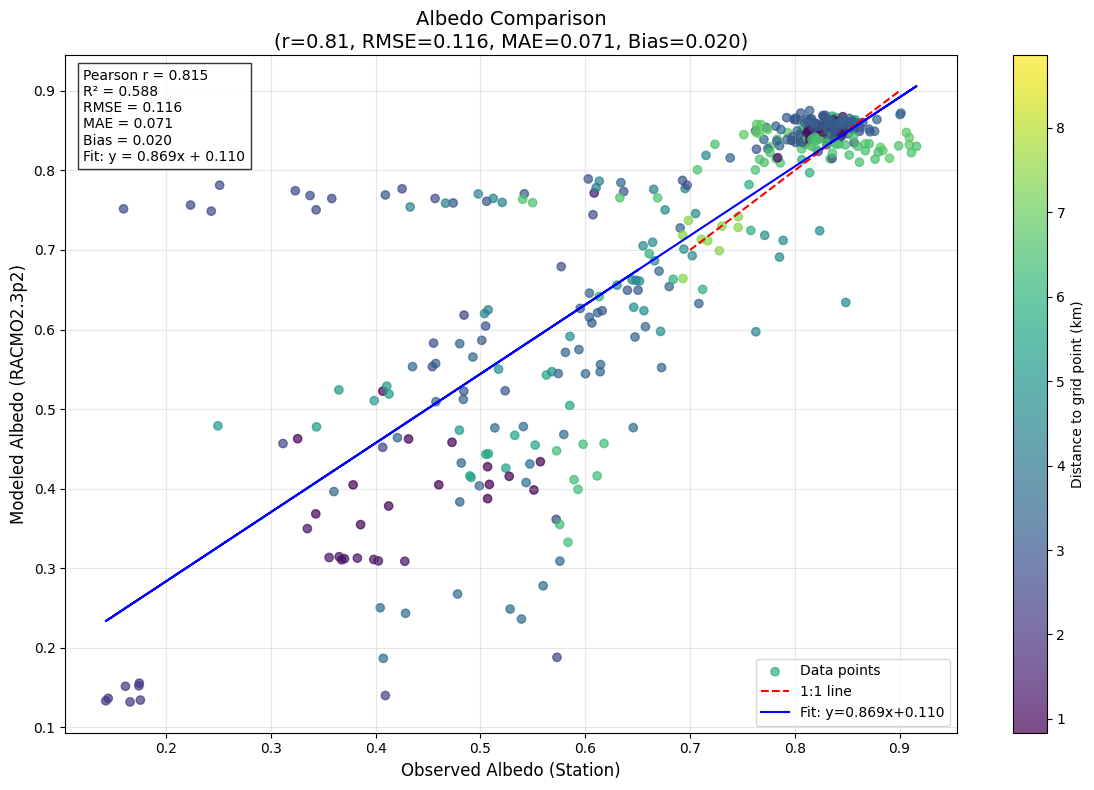

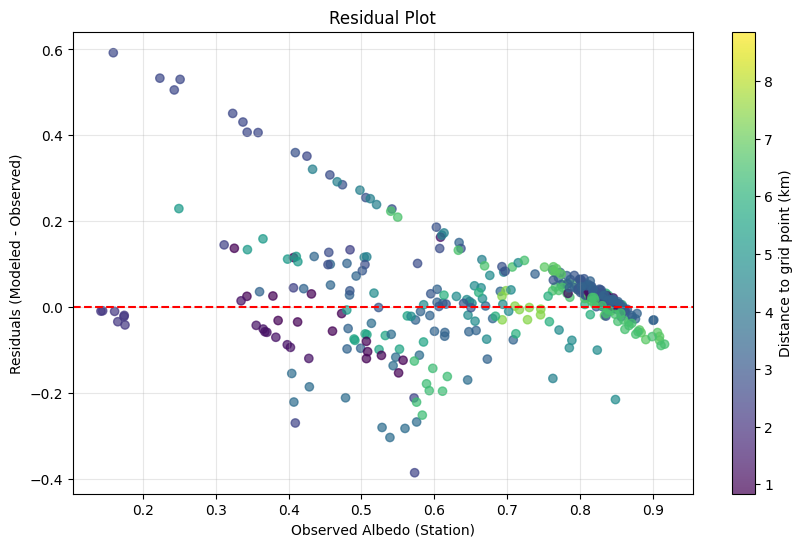

In [15]:
import xarray as xr
import pandas as pd
import numpy as np
from scipy.spatial import KDTree
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, linregress
from sklearn.metrics import mean_absolute_error, r2_score

# 1. 加载数据
nc_path = r"F:\TUB\greenlandProject\ERA5LAND\alb19582017RACMO2.3p2\greenland_albedo_cropped.nc"
csv_path = r"F:\TUB\greenlandProject\ERA5LAND\alb19582017RACMO2.3p2\summer_albedo_mean.csv"

ds = xr.open_dataset(nc_path)
df = pd.read_csv(csv_path)

# 2. 转换CSV年份为整数
df['year'] = df['year'].astype(int)

# 3. 准备NetCDF网格点
valid_mask = (~np.isnan(ds.lon.values)) & (~np.isnan(ds.lat.values))
nc_lons_valid = ds.lon.values[valid_mask]
nc_lats_valid = ds.lat.values[valid_mask]
nc_points = np.column_stack([nc_lons_valid, nc_lats_valid])
tree = KDTree(nc_points)

# 4. 对每个CSV点进行处理
results = []
for idx, row in df.iterrows():
    try:
        # 获取坐标和年份（确保为整数）
        csv_lon, csv_lat = row['longitude'], row['latitude']
        year = int(row['year'])
        
        # 空间匹配：找到最近的网格点
        dist, idx = tree.query([[csv_lon, csv_lat]])
        nearest_lon, nearest_lat = nc_lons_valid[idx[0]], nc_lats_valid[idx[0]]
        
        # 获取原始网格索引
        original_idx = np.where((ds.lon.values == nearest_lon) & 
                              (ds.lat.values == nearest_lat))
        rlat_idx, rlon_idx = original_idx[0][0], original_idx[1][0]
        
        # 时间匹配：找到对应年份的数据（每年只有7月16日一个时间点）
        nc_albedo = ds.alb.sel(time=str(year)).isel(
            height=0, 
            rlat=rlat_idx, 
            rlon=rlon_idx
        ).item()
        
        results.append({
            'year': year,
            'csv_lon': csv_lon,
            'csv_lat': csv_lat,
            'nc_lon': nearest_lon,
            'nc_lat': nearest_lat,
            'csv_albedo': row['albedo'],
            'nc_albedo': nc_albedo,
            'distance_km': dist[0] * 111  # 转换为公里
        })
        
    except Exception as e:
        #print(f"跳过 {row['year']} 年: {str(e)}")
        continue

# 5. 转换为DataFrame
result_df = pd.DataFrame(results)

if not result_df.empty:
    print(f"\n成功匹配 {len(result_df)}/{len(df)} 个数据点")
    print(result_df[['year', 'csv_lon', 'csv_lat', 'nc_albedo', 'csv_albedo', 'distance_km']].head())
    
    # 计算统计指标
    x = result_df['csv_albedo']
    y = result_df['nc_albedo']
    
    # 基本统计量
    corr, p_value = pearsonr(x, y)
    rmse = np.sqrt(np.mean((x - y)**2))
    mae = mean_absolute_error(x, y)
    bias = np.mean(y - x)
    r2 = r2_score(x, y)
    
    # 线性回归拟合
    slope, intercept, r_value, p_value_reg, std_err = linregress(x, y)
    reg_line = slope * x + intercept
    
    # 打印统计结果
    print("\n统计指标:")
    print(f"皮尔逊相关系数: {corr:.3f} (p={p_value:.3e})")
    print(f"R²分数: {r2:.3f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"MAE: {mae:.4f}")
    print(f"偏差(Bias): {bias:.4f}")
    print(f"线性回归: y = {slope:.3f}x + {intercept:.3f}")
    print(f"回归R值: {r_value:.3f} (p={p_value_reg:.3e})")
    
    # 可视化
    plt.figure(figsize=(12, 8))
    
    # 散点图
    sc = plt.scatter(x, y, c=result_df['distance_km'], 
                    cmap='viridis', alpha=0.7, label='Data points')
    plt.colorbar(sc, label='Distance to grid point (km)')
    
    # 1:1线
    plt.plot([0.7, 0.9], [0.7, 0.9], 'r--', label='1:1 line')
    
    # 拟合线
    plt.plot(x, reg_line, 'b-', label=f'Fit: y={slope:.3f}x+{intercept:.3f}')
    
    plt.xlabel('Observed Albedo (Station)', fontsize=12)
    plt.ylabel('Modeled Albedo (RACMO2.3p2)', fontsize=12)
    plt.title(f'Albedo Comparison\n(r={corr:.2f}, RMSE={rmse:.3f}, MAE={mae:.3f}, Bias={bias:.3f})', 
              fontsize=14)
    
    # 添加统计信息文本框
    stats_text = (f'Pearson r = {corr:.3f}\n'
                 f'R² = {r2:.3f}\n'
                 f'RMSE = {rmse:.3f}\n'
                 f'MAE = {mae:.3f}\n'
                 f'Bias = {bias:.3f}\n'
                 f'Fit: y = {slope:.3f}x + {intercept:.3f}')
    plt.gca().text(0.02, 0.98, stats_text, transform=plt.gca().transAxes,
                  verticalalignment='top', bbox=dict(facecolor='white', alpha=0.8))
    
    plt.grid(alpha=0.3)
    plt.legend(loc='lower right')
    plt.tight_layout()
    plt.show()
    
    # 保存结果
    result_df.to_csv('albedo_comparison_results.csv', index=False)
    
    # 绘制残差图
    residuals = y - x
    plt.figure(figsize=(10, 6))
    plt.scatter(x, residuals, c=result_df['distance_km'], cmap='viridis', alpha=0.7)
    plt.colorbar(label='Distance to grid point (km)')
    plt.axhline(y=0, color='r', linestyle='--')
    plt.xlabel('Observed Albedo (Station)')
    plt.ylabel('Residuals (Modeled - Observed)')
    plt.title('Residual Plot')
    plt.grid(alpha=0.3)
    plt.show()
    
else:
    print("\n没有匹配到任何数据点！")

# 关闭文件
ds.close()

In [ ]:
"C:\Users\11823\era5land\greenland_albedo_regional_analysis_1958_2017.csv"

In [1]:
# -*- coding: utf-8 -*-
import os
import warnings
from datetime import datetime

import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd

from shapely import ops
from shapely.geometry import shape
from shapely.vectorized import contains as shp_contains

# ========== 配置 ==========
nc_file   = r"D:\TUB\greenlandProject\ERA5LAND\alb19582017RACMO2.3p2\greenland_albedo_cropped.nc"
shp_dir   = r"C:\greenland\Greenland_shp\流域冰盖\new"
output_csv = r"RACMOjjaMeanShp.csv"

warnings.filterwarnings("ignore", category=FutureWarning)

def find_lat_lon(ds, spatial_dims):
    """
    在数据集中寻找与 alb 空间维度匹配的 lat/lon 变量（可为 2D）。
    优先尝试常见命名。
    """
    cand_lat = ["lat", "latitude", "nav_lat", "y"]
    cand_lon = ["lon", "longitude", "nav_lon", "x"]

    lat_name = next((n for n in cand_lat if n in ds.variables and set(ds[n].dims) >= set(spatial_dims)), None)
    lon_name = next((n for n in cand_lon if n in ds.variables and set(ds[n].dims) >= set(spatial_dims)), None)

    if lat_name is None or lon_name is None:
        # 退而求其次：允许 lat/lon 维度子集不完全相同，但形状可广播
        lat_name = lat_name or next((n for n in cand_lat if n in ds.variables), None)
        lon_name = lon_name or next((n for n in cand_lon if n in ds.variables), None)

    if lat_name is None or lon_name is None:
        raise ValueError("未找到与空间网格匹配的 lat/lon 变量，请检查 NetCDF 中纬度/经度变量的名称。")

    return lat_name, lon_name


def squeeze_singleton_vertical(da):
    """
    若存在单层的垂直/高度维（height/level/lev/z/h），自动剔除。
    """
    for dim in ["height", "level", "lev", "z", "h"]:
        if dim in da.dims and da.sizes.get(dim, 1) == 1:
            da = da.isel({dim: 0}, drop=True)
    return da


def wrap_longitude(lon_da):
    """
    若经度为 [0, 360]，转换为 [-180, 180]，以便与 EPSG:4326 的 shp 匹配。
    """
    lon = lon_da.values
    if np.nanmax(lon) > 180.0:
        lon = ((lon + 180.0) % 360.0) - 180.0
    return lon


def load_and_union_regions(shp_dir_path):
    """
    读取目录下所有 .shp；将同一文件（可能含多个要素）union 成一个 Multi/Polygon。
    返回 dict: {region_name: shapely_geometry}
    """
    shp_files = [f for f in os.listdir(shp_dir_path) if f.lower().endswith(".shp")]
    if not shp_files:
        raise FileNotFoundError(f"目录中未找到 .shp 文件: {shp_dir_path}")

    regions = {}
    for shp_file in shp_files:
        region_name = os.path.splitext(shp_file)[0]
        gdf = gpd.read_file(os.path.join(shp_dir_path, shp_file))

        # 统一到 WGS84
        if gdf.crs is None:
            # 常见格陵兰 shp 多为 WGS84，如不是请改这里
            gdf.set_crs(epsg=4326, inplace=True)
        else:
            gdf = gdf.to_crs(epsg=4326)

        # 修复可能的几何错误并 union
        fixed_geoms = [geom.buffer(0) if geom is not None else None for geom in gdf.geometry]
        fixed_geoms = [geom for geom in fixed_geoms if geom is not None]
        if not fixed_geoms:
            print(f"警告：{shp_file} 中没有有效几何，跳过。")
            continue

        union_geom = ops.unary_union(fixed_geoms)
        regions[region_name] = union_geom

    if not regions:
        raise RuntimeError("未能从 shapefile 聚合出任何有效区域。")
    return regions


def compute_region_means_for_jja(alb, years, lat2d, lon2d, regions_dict):
    """
    对每个区域计算逐年 JJA 空间均值。
    alb: DataArray [year, y, x] 或 [year, rlat, rlon]（已做过 groupby.year.mean）
    years: 升序年份列表
    lat2d/lon2d: 与 alb 空间维形状一致的 2D 数组
    regions_dict: {region_name: shapely_geom}
    """
    # 识别 alb 的空间维
    spatial_dims = [d for d in alb.dims if d not in ("time", "year")]
    if len(spatial_dims) != 2:
        raise ValueError(f"期望 2 个空间维，当前 alb.dims={alb.dims}")

    results = pd.DataFrame(index=years)
    results.index.name = "year"

    # 预先把 lon/lat 转为 np.array，并确保形状匹配
    latA = np.asarray(lat2d)
    lonA = np.asarray(lon2d)
    
    # 检查经纬度数组形状是否与 alb 空间维匹配
    alb_spatial_shape = tuple(alb.sizes[dim] for dim in spatial_dims)
    if latA.shape != alb_spatial_shape or lonA.shape != alb_spatial_shape:
        print(f"警告：经纬度数组形状 {latA.shape} 与 alb 空间形状 {alb_spatial_shape} 不匹配")
        # 尝试广播或调整
        if latA.ndim == 1 and lonA.ndim == 1:
            lonA, latA = np.meshgrid(lonA, latA)
    
    # 展平经纬度数组用于 shapely.vectorized.contains
    lat_flat = latA.flatten()
    lon_flat = lonA.flatten()
    valid_mask = ~(np.isnan(lat_flat) | np.isnan(lon_flat))
    
    # 对每个区域构造一次 mask，随后在所有年份上复用
    region_masks = {}
    for rname, geom in regions_dict.items():
        geom = geom.buffer(0)  # 再保险一次
        print(f"处理区域: {rname}")
        
        # 只对有效点进行包含性检测
        mask_flat = np.zeros(len(lat_flat), dtype=bool)
        if np.any(valid_mask):
            mask_flat[valid_mask] = shp_contains(geom, lon_flat[valid_mask], lat_flat[valid_mask])
        
        # 重新整形为原始空间形状
        mask = mask_flat.reshape(latA.shape)
        
        if not np.any(mask):
            print(f"警告：区域 {rname} 与网格无重叠（mask 全 False）。")
        else:
            print(f"区域 {rname} 包含 {np.sum(mask)} 个有效网格点")
        
        region_masks[rname] = mask

    # 逐区域逐年计算
    for rname, mask in region_masks.items():
        vals = []
        for y in years:
            # 获取对应年份的数据
            field = alb.sel(year=y).values  # 2D
            
            # 应用区域mask并计算均值
            masked_field = np.where(mask, field, np.nan)
            
            # 计算均值，忽略NaN
            if np.any(~np.isnan(masked_field)):
                mean_val = np.nanmean(masked_field)
            else:
                mean_val = np.nan
                
            vals.append(mean_val)
            
        results[rname] = vals

    return results


def main():
    try:
        print(">>> 读取 NetCDF ...")
        # decode_times=True 让 xarray 直接解码时间为 datetime64
        ds = xr.open_dataset(nc_file, decode_times=True)
        print(f"数据集维度: {dict(ds.dims)}")
        print(f"数据集变量: {list(ds.variables.keys())}")

        # 取 alb 变量
        if "alb" not in ds.variables:
            raise KeyError("数据集中未找到变量 'alb'，请检查变量名。")
        alb = ds["alb"]
        print(f"alb 维度: {alb.dims}, 形状: {alb.shape}")

        # 剔除单层的垂直维（若有）
        alb = squeeze_singleton_vertical(alb)
        print(f"压缩后 alb 维度: {alb.dims}, 形状: {alb.shape}")

        # 识别 alb 空间维（2 个）
        spatial_dims = [d for d in alb.dims if d not in ("time", "year")]
        if len(spatial_dims) < 2:
            raise ValueError(f"未识别到 2 个空间维，alb.dims = {alb.dims}")
        print(f"空间维度: {spatial_dims}")

        # 找到 lat/lon 变量，并拿到与空间维匹配的 2D 经纬度
        lat_name, lon_name = find_lat_lon(ds, spatial_dims)
        print(f"使用的纬度变量: {lat_name}, 经度变量: {lon_name}")
        
        lat = ds[lat_name]
        lon = ds[lon_name]
        print(f"纬度范围: {float(lat.min()):.2f} - {float(lat.max()):.2f}")
        print(f"经度范围: {float(lon.min()):.2f} - {float(lon.max()):.2f}")

        # 若经度是 0–360，改为 -180–180
        lon_wrapped = wrap_longitude(lon)
        print(f"经度范围（处理后）: {np.nanmin(lon_wrapped):.2f} - {np.nanmax(lon_wrapped):.2f}")

        # 只保留 JJA，并在时间维上按年平均
        if "time" not in alb.dims:
            raise ValueError("变量 'alb' 缺少时间维 'time'，无法计算逐年 JJA。")

        print(">>> 计算 JJA（6-8月）逐年均值 ...")
        # 检查时间范围
        time_range = pd.to_datetime(alb["time"].values)
        print(f"时间范围: {time_range.min()} - {time_range.max()}")
        
        is_jja = alb["time"].dt.month.isin([6, 7, 8])
        jja_count = is_jja.sum().values
        print(f"JJA 月份数据点数: {jja_count}")
        
        if jja_count == 0:
            raise ValueError("未找到 JJA（6-8月）的数据")
        
        alb_jja_year = (
            alb.where(is_jja, drop=True)
               .groupby("time.year")
               .mean("time", skipna=True)
        ).transpose("year", *spatial_dims)

        years = list(map(int, np.asarray(alb_jja_year["year"].values)))
        years.sort()
        print(f"可用年份: {min(years)} - {max(years)} (共 {len(years)} 年)")

        # 读取并 union 各分区
        print(">>> 读取/合并 shapefile 分区 ...")
        regions = load_and_union_regions(shp_dir)
        print(f"找到 {len(regions)} 个流域分区: {list(regions.keys())}")

        # 计算每个区域逐年 JJA 的空间均值
        print(">>> 计算各区域年均值 ...（这一步看区域数与网格大小，可能稍耗时）")
        results = compute_region_means_for_jja(
            alb=alb_jja_year,
            years=years,
            lat2d=lat.values,
            lon2d=lon_wrapped,
            regions_dict=regions
        )

        # 检查结果
        print(">>> 结果统计:")
        for col in results.columns:
            valid_count = results[col].notna().sum()
            mean_val = results[col].mean()
            print(f"{col}: 有效年份 {valid_count}/{len(years)}, 平均值 {mean_val:.4f}")

        # 保存
        results.to_csv(output_csv, float_format="%.6f")
        print(f"✔ 结果已保存: {output_csv}")
        print("=== 结果预览（前5行）===")
        print(results.head())

    except Exception as e:
        print(f"[错误] {e}")
        import traceback
        traceback.print_exc()
    finally:
        try:
            ds.close()
        except:
            pass


if __name__ == "__main__":
    main()


>>> 读取 NetCDF ...
数据集维度: {'time': 60, 'height': 1, 'rlat': 566, 'rlon': 438}
数据集变量: ['time', 'height', 'alb', 'lon', 'lat']
alb 维度: ('time', 'height', 'rlat', 'rlon'), 形状: (60, 1, 566, 438)
压缩后 alb 维度: ('time', 'rlat', 'rlon'), 形状: (60, 566, 438)
空间维度: ['rlat', 'rlon']
使用的纬度变量: lat, 经度变量: lon
纬度范围: 55.57 - 85.85
经度范围: -105.70 - 34.11
经度范围（处理后）: -105.70 - 34.11
>>> 计算 JJA（6-8月）逐年均值 ...
时间范围: 1958-07-16 12:00:00 - 2017-07-16 12:00:00
JJA 月份数据点数: 60
可用年份: 1958 - 2017 (共 60 年)
>>> 读取/合并 shapefile 分区 ...
找到 3 个流域分区: ['dong', 'xi', 'xiaorong']
>>> 计算各区域年均值 ...（这一步看区域数与网格大小，可能稍耗时）
处理区域: dong
区域 dong 包含 24073 个有效网格点
处理区域: xi
区域 xi 包含 32877 个有效网格点
处理区域: xiaorong
区域 xiaorong 包含 13075 个有效网格点
>>> 结果统计:
dong: 有效年份 60/60, 平均值 0.8205
xi: 有效年份 60/60, 平均值 0.8216
xiaorong: 有效年份 60/60, 平均值 0.3571
[错误] [Errno 13] Permission denied: 'RACMOjjaMeanShp.csv'


Traceback (most recent call last):
  File "C:\Users\11823\AppData\Local\Temp\ipykernel_16748\762249038.py", line 263, in main
    results.to_csv(output_csv, float_format="%.6f")
    ~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\anaconda3\Lib\site-packages\pandas\util\_decorators.py", line 333, in wrapper
    return func(*args, **kwargs)
  File "c:\anaconda3\Lib\site-packages\pandas\core\generic.py", line 3967, in to_csv
    return DataFrameRenderer(formatter).to_csv(
           ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^
        path_or_buf,
        ^^^^^^^^^^^^
    ...<14 lines>...
        storage_options=storage_options,
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "c:\anaconda3\Lib\site-packages\pandas\io\formats\format.py", line 1014, in to_csv
    csv_formatter.save()
    ~~~~~~~~~~~~~~~~~~^^
  File "c:\anaconda3\Lib\site-packages\pandas\io\formats\csvs.py", line 251, in save
    with get_handle(
         ~~~~~~~~~~^
        self.filepath_or_buffer,
        ^^

C:\Users\11823\AppData\Local\Temp\ipykernel_16748\1341446456.py:42: UserWarning: Glyph 19977 (\N{CJK UNIFIED IDEOGRAPH-4E09}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\11823\AppData\Local\Temp\ipykernel_16748\1341446456.py:42: UserWarning: Glyph 20010 (\N{CJK UNIFIED IDEOGRAPH-4E2A}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\11823\AppData\Local\Temp\ipykernel_16748\1341446456.py:42: UserWarning: Glyph 27969 (\N{CJK UNIFIED IDEOGRAPH-6D41}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\11823\AppData\Local\Temp\ipykernel_16748\1341446456.py:42: UserWarning: Glyph 22495 (\N{CJK UNIFIED IDEOGRAPH-57DF}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\11823\AppData\Local\Temp\ipykernel_16748\1341446456.py:42: UserWarning: Glyph 24180 (\N{CJK UNIFIED IDEOGRAPH-5E74}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\11823\AppData\Local\Temp\ipykernel_16748\1341446456.py:42: UserWarning: Glyph 22343 (\

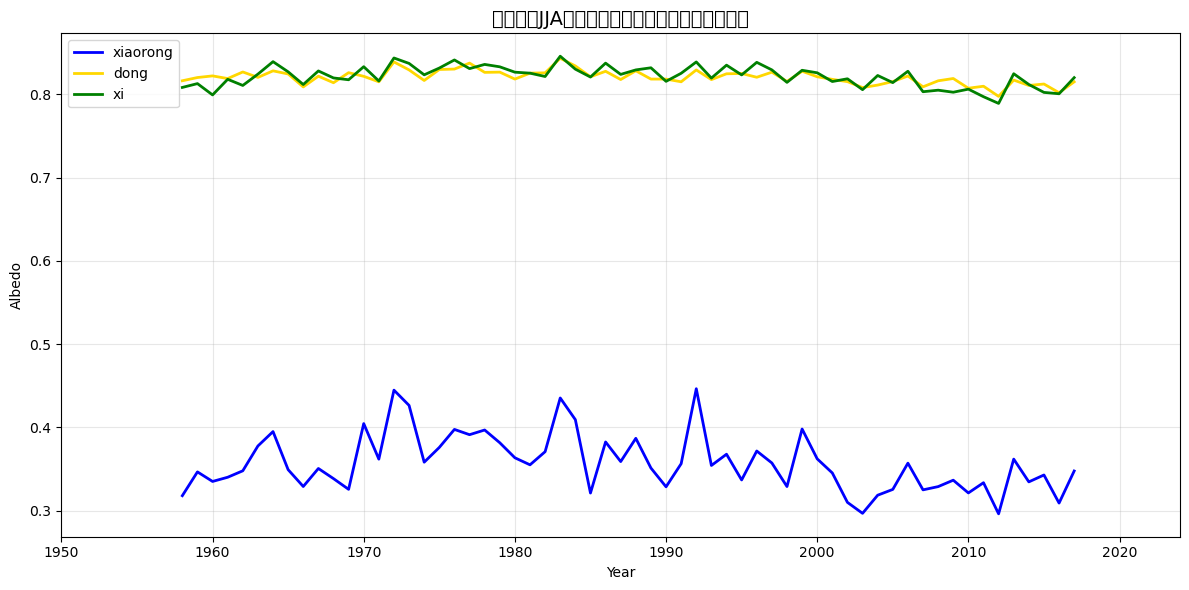

C:\Users\11823\AppData\Local\Temp\ipykernel_16748\1341446456.py:57: UserWarning: Glyph 19977 (\N{CJK UNIFIED IDEOGRAPH-4E09}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\11823\AppData\Local\Temp\ipykernel_16748\1341446456.py:57: UserWarning: Glyph 20010 (\N{CJK UNIFIED IDEOGRAPH-4E2A}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\11823\AppData\Local\Temp\ipykernel_16748\1341446456.py:57: UserWarning: Glyph 27969 (\N{CJK UNIFIED IDEOGRAPH-6D41}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\11823\AppData\Local\Temp\ipykernel_16748\1341446456.py:57: UserWarning: Glyph 22495 (\N{CJK UNIFIED IDEOGRAPH-57DF}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\11823\AppData\Local\Temp\ipykernel_16748\1341446456.py:57: UserWarning: Glyph 21464 (\N{CJK UNIFIED IDEOGRAPH-53D8}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\11823\AppData\Local\Temp\ipykernel_16748\1341446456.py:57: UserWarning: Glyph 24322 (\

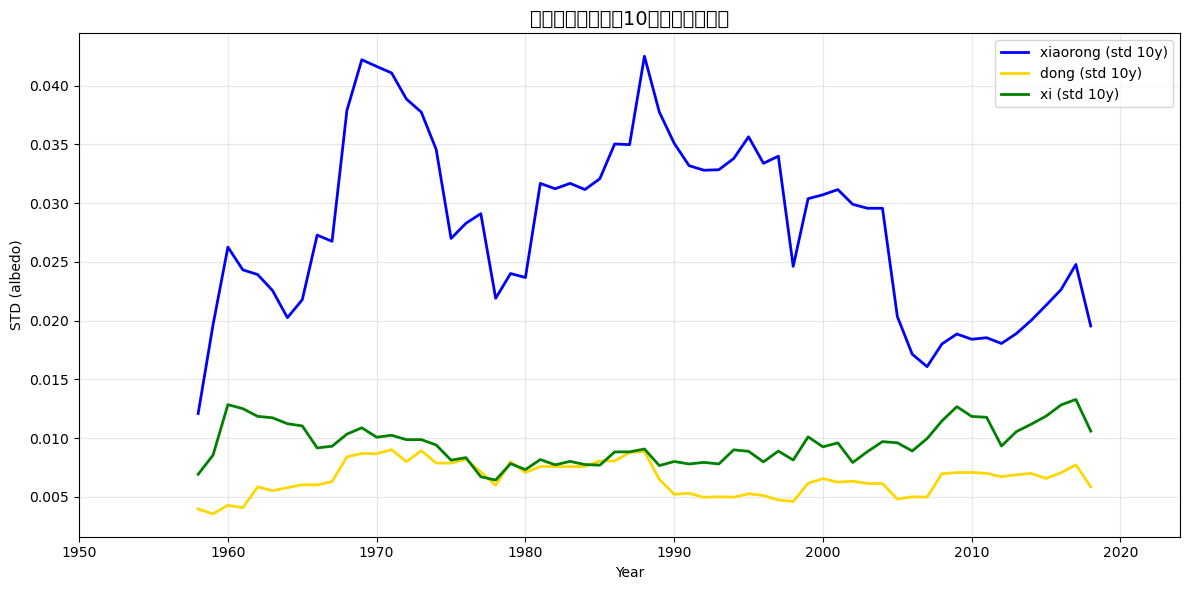


=== 整段趋势（1950–2024） ===
xiaorong : slope=-0.0065/decade, R²=0.108, p=0.0102, N=60
dong     : slope=-0.0023/decade, R²=0.220, p=0.000159, N=60
xi       : slope=-0.0025/decade, R²=0.118, p=0.00732, N=60

=== 分段趋势（< 1990） ===
xiaorong : slope=+0.0120/decade, R²=0.118, p=0.0547, N=32
dong     : slope=+0.0025/decade, R²=0.096, p=0.0841, N=32
xi       : slope=+0.0061/decade, R²=0.273, p=0.00216, N=32

=== 分段趋势（≥ 2000） ===
xiaorong : slope=+0.0012/decade, R²=0.001, p=0.9, N=18
dong     : slope=-0.0050/decade, R²=0.175, p=0.0838, N=18
xi       : slope=-0.0079/decade, R²=0.146, p=0.117, N=18

=== 变异性趋势（10年滑动STD, 1950–2024） ===
xiaorong : slope=-0.0011/decade, R²=0.074, p=0.0342, N=61
dong     : slope=-0.0000/decade, R²=0.001, p=0.832, N=61
xi       : slope=+0.0002/decade, R²=0.033, p=0.163, N=61

=== 变异性趋势（10年滑动STD, < 1990） ===
xiaorong : slope=+0.0040/decade, R²=0.247, p=0.00382, N=32
dong     : slope=+0.0011/decade, R²=0.427, p=5.07e-05, N=32
xi       : slope=-0.0011/decade, R²=0.372, p=0.00

In [2]:
# -*- coding: utf-8 -*-
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress

# ========= 配置 =========
csv_path = r'RACMOjjaMeanShp.csv'  # 替换为你的CSV路径
year_min, year_max = 1950, 2024
pre_cut, post_cut = 1990, 2000
rolling_win = 10  # 变异性用10年滑动标准差

# ========= 读数与整理 =========
df = pd.read_csv(csv_path)
# 容错列名大小写
df.columns = [c.strip().lower() for c in df.columns]
df = df.rename(columns={'xiaorong':'xiaorong', 'dong':'dong', 'xi':'xi'})

# 只保留必要列
df = df[['year', 'dong', 'xi', 'xiaorong']]
df = df.dropna(subset=['year'])
df['year'] = df['year'].astype(int)
df = df[(df['year'] >= year_min) & (df['year'] <= year_max)].set_index('year').sort_index()

# 用完整年序列对齐（缺失年保留NaN，这样画图会断线）
years_full = pd.Index(range(year_min, year_max + 1), name='year')
df = df.reindex(years_full)

basins = ['xiaorong', 'dong', 'xi']
colors = {'xiaorong': 'blue', 'dong': 'gold', 'xi': 'green'}

# ========= 绘图：三个流域变化折线图 =========
plt.figure(figsize=(12, 6))
for b in basins:
    plt.plot(df.index, df[b], color=colors[b], linewidth=2, label=b)
plt.title('三个流域JJA年均反照率变化（缺失年份不连接）', fontsize=14)
plt.xlabel('Year')
plt.ylabel('Albedo')
plt.xlim(year_min, year_max)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# ========= 变异性趋势（10年滑动标准差） =========
rolling_std = df[basins].rolling(window=rolling_win, center=True, min_periods=5).std()

plt.figure(figsize=(12, 6))
for b in basins:
    plt.plot(rolling_std.index, rolling_std[b], color=colors[b], linewidth=2, label=f'{b} (std {rolling_win}y)')
plt.title(f'三个流域变异性（{rolling_win}年滑动标准差）', fontsize=14)
plt.xlabel('Year')
plt.ylabel('STD (albedo)')
plt.xlim(year_min, year_max)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

def slope_per_decade(series: pd.Series):
    s = series.dropna()
    if len(s) < 3:
        return np.nan, np.nan, np.nan
    x = s.index.values.astype(float)
    y = s.values.astype(float)
    lr = linregress(x, y)
    return lr.slope * 10.0, lr.rvalue**2, lr.pvalue

def print_trend(title, series_dict):
    print(f'\n=== {title} ===')
    for b, s in series_dict.items():
        slope10, r2, p = slope_per_decade(s)
        print(f'{b:9s}: slope={slope10:+.4f}/decade, R²={r2:.3f}, p={p:.3g}, N={s.dropna().size}')

# ========= 整段趋势（1950–2024） =========
print_trend('整段趋势（1950–2024）', {b: df[b] for b in basins})

# ========= 分段趋势：1990年之前，2000年及之后 =========
df_pre = df[df.index < pre_cut]
df_post = df[df.index >= post_cut]

print_trend(f'分段趋势（< {pre_cut}）', {b: df_pre[b] for b in basins})
print_trend(f'分段趋势（≥ {post_cut}）', {b: df_post[b] for b in basins})

# ========= 变异性趋势（对10年滑动STD做趋势） =========
print_trend(f'变异性趋势（{rolling_win}年滑动STD, 1950–2024）', {b: rolling_std[b] for b in basins})
print_trend(f'变异性趋势（{rolling_win}年滑动STD, < {pre_cut}）', {b: rolling_std.loc[rolling_std.index < pre_cut, b] for b in basins})
print_trend(f'变异性趋势（{rolling_win}年滑动STD, ≥ {post_cut}）', {b: rolling_std.loc[rolling_std.index >= post_cut, b] for b in basins})

# ========= 异常年检测（±2σ） =========
print('\n=== 异常年（±2σ） ===')
for b in basins:
    s = df[b].dropna()
    mu, sd = s.mean(), s.std()
    high = s[s > mu + 2*sd].index.tolist()
    low  = s[s < mu - 2*sd].index.tolist()
    print(f'{b:9s}: 高异常{len(high)}年: {high}')
    print(f'{"":9s} 低异常{len(low)}年: {low}')

# 可选：将关键结果导出
out_summary = []
for seg_name, seg_df in [('full', df), (f'<{pre_cut}', df_pre), (f'>={post_cut}', df_post)]:
    for b in basins:
        slope10, r2, p = slope_per_decade(seg_df[b])
        out_summary.append({'segment': seg_name, 'basin': b, 'slope_per_decade': slope10, 'R2': r2, 'p': p})

summary_df = pd.DataFrame(out_summary)
# summary_df.to_csv('basin_trend_summary.csv', index=False, encoding='utf-8-sig')
print('\n趋势汇总（预览）:\n', summary_df.head())
